# ML Assignment 3 - Neural network classifier for bank customer churn

**Problem statement:** given a bank customer's attributes (credit score, geography, gender, age, tenure, balance, ...) build a neural network that predicts whether the customer will leave (`Exited = 1`). Read the data, split features/target and train/test, normalise, build the model, improve it, and print the accuracy score and confusion matrix.

**Libraries used:** pandas, numpy (data), scikit-learn (`StandardScaler`, `MLPClassifier`, metrics), matplotlib/seaborn (plots).

**Driver:** the Kaggle *Churn_Modelling* CSV (10,000 rows, 14 columns) is not available offline, so a seeded synthetic table with the same columns is generated. To use the real file set `CSV_PATH = "Churn_Modelling.csv"`. No input is taken at runtime.

In [1]:
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")  # the deliberately short baseline run would warn about convergence
CSV_PATH = None  # e.g. "Churn_Modelling.csv"

## 1. Read the dataset

In [2]:
def make_data(n=10000, seed=7):
    rng = np.random.default_rng(seed)
    df = pd.DataFrame({
        "RowNumber": np.arange(1, n + 1),
        "CustomerId": rng.integers(15_000_000, 16_000_000, n),
        "Surname": rng.choice(["Smith", "Rao", "Khan", "Patel", "Singh"], n),
        "CreditScore": rng.normal(650, 90, n).clip(350, 850).astype(int),
        "Geography": rng.choice(["France", "Germany", "Spain"], n, p=[0.5, 0.25, 0.25]),
        "Gender": rng.choice(["Male", "Female"], n),
        "Age": rng.normal(39, 10, n).clip(18, 90).astype(int),
        "Tenure": rng.integers(0, 11, n),
        "Balance": np.where(rng.random(n) < 0.35, 0, rng.normal(120000, 30000, n)).clip(0),
        "NumOfProducts": rng.choice([1, 2, 3, 4], n, p=[0.5, 0.45, 0.04, 0.01]),
        "HasCrCard": rng.integers(0, 2, n),
        "IsActiveMember": rng.integers(0, 2, n),
        "EstimatedSalary": rng.uniform(10000, 200000, n),
    })
    score = (-1.7 + 0.09 * (df.Age - 39) + 1.3 * (df.Geography == "Germany") + 0.6 * (df.Gender == "Female")
             - 1.3 * df.IsActiveMember + 0.000004 * df.Balance
             + 2.2 * (df.NumOfProducts >= 3)                                          # non-linear effects the
             + 1.5 * ((df.Balance > 110000) & (df.Geography == "Germany"))            # larger network can learn
             - 1.6 * ((df.Age < 32) & (df.IsActiveMember == 1)))
    df["Exited"] = (rng.random(n) < 1 / (1 + np.exp(-score))).astype(int)
    return df


df = pd.read_csv(CSV_PATH) if CSV_PATH else make_data()
print(f"Dataset: {df.shape[0]} rows x {df.shape[1]} columns, churn rate {df['Exited'].mean():.1%}")
print(df.head(3).to_string())

Dataset: 10000 rows x 14 columns, churn rate 28.1%
   RowNumber  CustomerId Surname  CreditScore Geography  Gender  Age  Tenure        Balance  NumOfProducts  HasCrCard  IsActiveMember  EstimatedSalary  Exited
0          1    15944904    Khan          686    France  Female   60       4   63637.942540              1          1               1     56360.600737       1
1          2    15625095    Khan          669     Spain    Male   30       5  160204.656244              2          1               0     15813.993611       0
2          3    15684179   Smith          589   Germany    Male   40       1       0.000000              2          1               1    196418.356421       0


## 2. Features / target and train-test split
Identifier columns are dropped and the categorical columns (Geography, Gender) are one-hot encoded.

In [3]:
X = pd.get_dummies(df.drop(columns=["RowNumber", "CustomerId", "Surname", "Exited"]), drop_first=True)
y = df["Exited"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape, " Features:", list(X.columns))

Train: (8000, 11)  Test: (2000, 11)  Features: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain', 'Gender_Male']


## 3. Normalise (the scaler is fitted on the training set only)

In [4]:
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

## 4. Build the initial model

In [5]:
base = MLPClassifier(hidden_layer_sizes=(3,), max_iter=15, random_state=0).fit(X_train_s, y_train)
base_pred = base.predict(X_test_s)
print("Initial model (1 hidden layer of 3 neurons, 15 epochs)")
print("Accuracy:", round(accuracy_score(y_test, base_pred), 4))
print("Confusion matrix [[TN FP] [FN TP]]:\n", confusion_matrix(y_test, base_pred))

Initial model (1 hidden layer of 3 neurons, 15 epochs)
Accuracy: 0.651
Confusion matrix [[TN FP] [FN TP]]:
 [[1127  311]
 [ 387  175]]


## 5. Points of improvement
A bigger network (32-16 neurons), an L2 penalty (`alpha`) against over-fitting, and early stopping on a validation split.

Improved model (layers 32-16, L2 penalty, early stopping)
Accuracy: 0.785
Confusion matrix [[TN FP] [FN TP]]:
 [[1296  142]
 [ 288  274]]

Change in accuracy: +0.1340


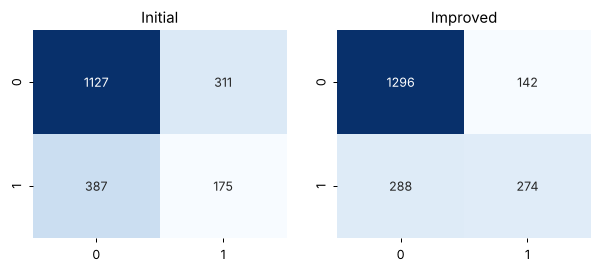

In [6]:
better = MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3, early_stopping=True, n_iter_no_change=15,
                       max_iter=500, random_state=0).fit(X_train_s, y_train)
better_pred = better.predict(X_test_s)
print("Improved model (layers 32-16, L2 penalty, early stopping)")
print("Accuracy:", round(accuracy_score(y_test, better_pred), 4))
print("Confusion matrix [[TN FP] [FN TP]]:\n", confusion_matrix(y_test, better_pred))
print(f"\nChange in accuracy: {accuracy_score(y_test, better_pred) - accuracy_score(y_test, base_pred):+.4f}")

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, (name, pred) in zip(axes, (("Initial", base_pred), ("Improved", better_pred))):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(name)

**Conclusion:** the accuracy score and confusion matrix of both models are printed above. Because only about one in five customers churn, also look at the false negatives (customers who left but were predicted to stay), not just the accuracy.